# Classifier comparison

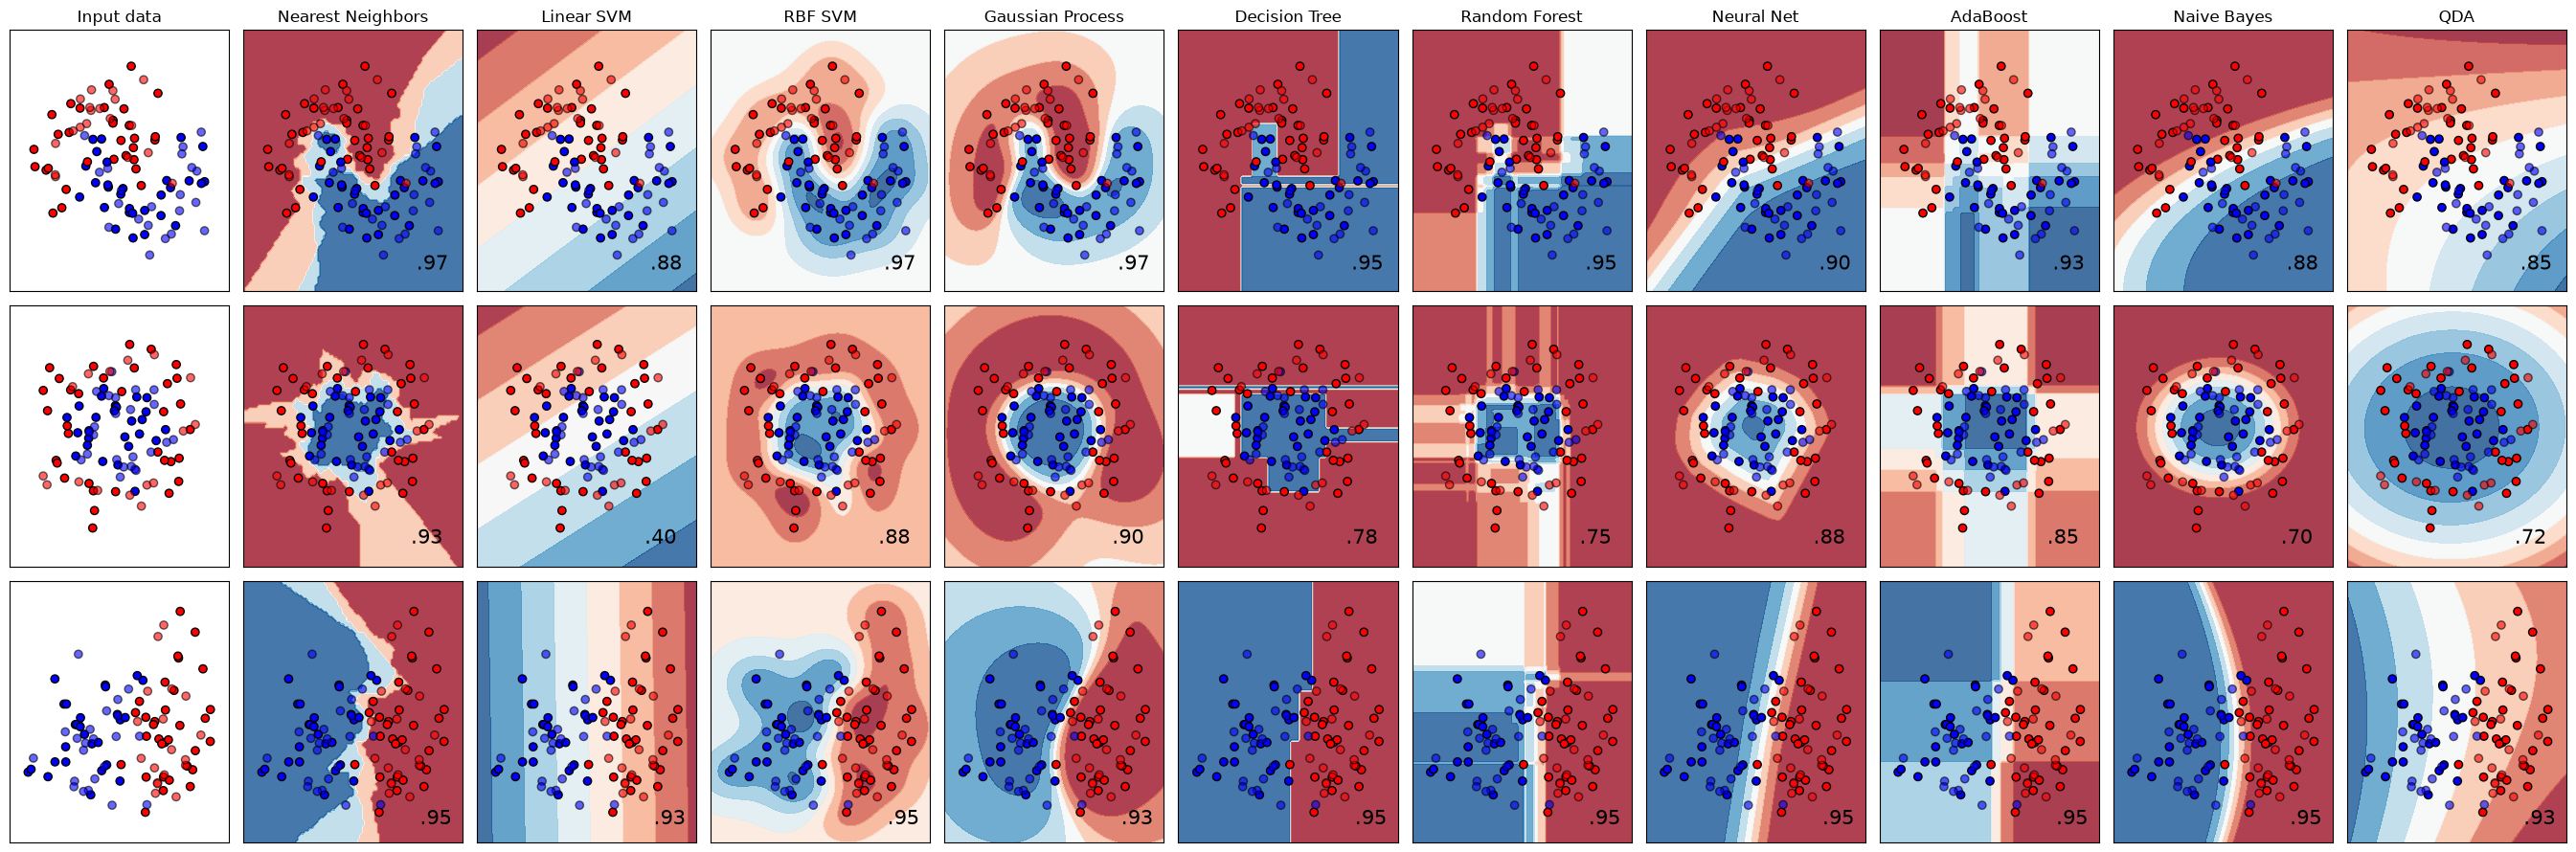

In [5]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_circles, make_classification, make_moons
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

names = [
    "Nearest Neighbors",
    "Linear SVM",
    "RBF SVM",
    "Gaussian Process",
    "Decision Tree",
    "Random Forest",
    "Neural Net",
    "AdaBoost",
    "Naive Bayes",
    "QDA",
]

classifiers = [
    KNeighborsClassifier(3),
    SVC(kernel="linear", C=0.025, random_state=42),
    SVC(gamma=2, C=1, random_state=42),
    GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42),
    DecisionTreeClassifier(max_depth=5, random_state=42),
    RandomForestClassifier(
        max_depth=5, n_estimators=10, max_features=1, random_state=42
    ),
    MLPClassifier(alpha=1, max_iter=1000, random_state=42),
    AdaBoostClassifier(random_state=42),
    GaussianNB(),
    QuadraticDiscriminantAnalysis(),
]

X, y = make_classification(
    n_features=2, n_redundant=0, n_informative=2, random_state=1, n_clusters_per_class=1
)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [
    make_moons(noise=0.3, random_state=0),
    make_circles(noise=0.2, factor=0.5, random_state=1),
    linearly_separable,
]

figure = plt.figure(figsize=(27, 9))
i = 1
# iterate over datasets
for ds_cnt, ds in enumerate(datasets):
    # preprocess dataset, split into training and test part
    X, y = ds
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.4, random_state=42
    )

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(["#FF0000", "#0000FF"])
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    if ds_cnt == 0:
        ax.set_title("Input data")
    # Plot the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k")
    # Plot the testing points
    ax.scatter(
        X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6, edgecolors="k"
    )
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(())
    ax.set_yticks(())
    i += 1

    # iterate over classifiers
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)

        clf = make_pipeline(StandardScaler(), clf)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)
        DecisionBoundaryDisplay.from_estimator(
            clf, X, cmap=cm, alpha=0.8, ax=ax, eps=0.5
        )

        # Plot the training points
        ax.scatter(
            X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright, edgecolors="k"
        )
        # Plot the testing points
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_test,
            cmap=cm_bright,
            edgecolors="k",
            alpha=0.6,
        )

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.set_xticks(())
        ax.set_yticks(())
        if ds_cnt == 0:
            ax.set_title(name)
        ax.text(
            x_max - 0.3,
            y_min + 0.3,
            ("%.2f" % score).lstrip("0"),
            size=15,
            horizontalalignment="right",
        )
        i += 1

plt.tight_layout()
plt.show()

# Classifier Comparison

## 1. Was ist das Ziel dieses Beispiels?
Das Beispiel von scikit-learn vergleicht zehn verschiedene Klassifikationsverfahren miteinander.

Alle Verfahren bekommen dieselben Datensätze. Anschließend wird untersucht:
- Wie teilt das jeweilige Verfahren die Daten in Klassen ein?
- Wo liegen die Grenzen zwischen den vorhergesagten Klassen?
- Wie gut klassifiziert das Verfahren bisher unbekannte Daten?
Das Hauptziel ist also, die unterschiedlichen Decision Boundaries (Entscheidungsgrenzen) sichtbar zu machen. Scikit-learn

## 2. Welche Daten werden verwendet?
Das Beispiel verwendet drei künstlich erzeugte Datensätze:

1. Moons: Die Datenpunkte bilden zwei halbmondförmige Strukturen.

2. Circles: Die Datenpunkte bilden zwei ineinanderliegende Kreise.

3. Linearly Separable: Die beiden Klassen lassen sich ungefähr durch eine gerade Linie voneinander trennen.
Warum verwendet man künstliche Daten?

Weil die Struktur der Daten bekannt ist. Dadurch lässt sich leichter erkennen, ob ein Klassifikationsverfahren die vorhandenen Muster gut erkennt.

## 3. Was passiert mit den Daten?
Jeder Datensatz wird in zwei Teile aufgeteilt:
- 60 % Training Data: Damit wird das Modell trainiert.
- 40 % Test Data: Damit wird anschließend überprüft, wie gut das trainierte Modell klassifiziert.
Das ist wichtig: Das Modell soll nicht nur die Trainingsdaten auswendig lernen, sondern auch mit bisher unbekannten Daten umgehen können. Scikit-learn

## 4. Was wird in der Grafik dargestellt?
Die Grafik besteht aus drei Zeilen und elf Spalten:
- Jede Zeile steht für einen der drei Datensätze.
- Die erste Spalte zeigt die ursprünglichen Daten.
- Die übrigen zehn Spalten zeigen, wie die verschiedenen Klassifikationsverfahren dieselben Daten einteilen.
Die zehn Verfahren sind:
1. Nearest Neighbors
2. Linear SVM
3. RBF SVM
4. Gaussian Process
5. Decision Tree
6. Random Forest
7. Neural Net
8. AdaBoost
9. Naive Bayes
10. QDA
Wie liest man die Grafik?
Es gibt drei wichtige Bestandteile:

### 1. Farbige Flächen

Die farbigen Flächen zeigen, welcher Klasse das jeweilige Modell einen bestimmten Bereich zuordnet.

Beispielsweise:
- Roter Bereich → Modell sagt Klasse 0 voraus.
- Blauer Bereich → Modell sagt Klasse 1 voraus.

### 2. Kreise bzw. Datenpunkte

Die Punkte zeigen die tatsächlichen Daten:
- Dunklere Punkte: Trainingsdaten.
- Transparente Punkte: Testdaten.
Die Farben der Punkte zeigen ihre tatsächliche Klassenzugehörigkeit.

### 3. Zahl unten rechts

Diese Zahl zeigt die Accuracy auf den Testdaten.

Beispiel: 0.85 bedeutet, dass das Modell 85 % der Testdaten korrekt klassifiziert hat.

## 5. Was ist eine Decision Boundary?
Das ist der wichtigste Begriff dieses Beispiels.

Eine Decision Boundary ist die Grenze zwischen zwei Bereichen, denen das Modell unterschiedliche Klassen zuordnet.

Stell dir vor, ein Modell soll rote und blaue Punkte unterscheiden.

Es muss entscheiden:
- Ab welchem Bereich gehört ein Punkt zur roten Klasse?
- Ab welchem Bereich gehört ein Punkt zur blauen Klasse?
Die Grenze zwischen diesen Bereichen ist die Decision Boundary.

Je nach Klassifikationsverfahren kann diese Grenze unterschiedlich aussehen:
- Eine gerade Linie
- Eine gekrümmte Linie
- Eine sehr unregelmäßige Grenze
Genau diese Unterschiede möchte das Beispiel sichtbar machen.

Linear and Quadratic Discriminant Analysis with covariance ellipsoid

Data generation

In [6]:
import numpy as np


def make_data(n_samples, n_features, cov_class_1, cov_class_2, seed=0):
    rng = np.random.RandomState(seed)
    X = np.concatenate(
        [
            rng.randn(n_samples, n_features) @ cov_class_1,
            rng.randn(n_samples, n_features) @ cov_class_2 + np.array([1, 1]),
        ]
    )
    y = np.concatenate([np.zeros(n_samples), np.ones(n_samples)])
    return X, y

In [7]:
covariance = np.array([[1, 0], [0, 1]])
X_isotropic_covariance, y_isotropic_covariance = make_data(
    n_samples=1_000,
    n_features=2,
    cov_class_1=covariance,
    cov_class_2=covariance,
    seed=0,
)
covariance = np.array([[0.0, -0.23], [0.83, 0.23]])
X_shared_covariance, y_shared_covariance = make_data(
    n_samples=300,
    n_features=2,
    cov_class_1=covariance,
    cov_class_2=covariance,
    seed=0,
)
cov_class_1 = np.array([[0.0, -1.0], [2.5, 0.7]]) * 2.0
cov_class_2 = cov_class_1.T
X_different_covariance, y_different_covariance = make_data(
    n_samples=300,
    n_features=2,
    cov_class_1=cov_class_1,
    cov_class_2=cov_class_2,
    seed=0,
)

Plotting Functions

In [8]:
import matplotlib as mpl
from matplotlib import colors

from sklearn.inspection import DecisionBoundaryDisplay


def plot_ellipse(mean, cov, color, ax):
    v, w = np.linalg.eigh(cov)
    u = w[0] / np.linalg.norm(w[0])
    angle = np.arctan(u[1] / u[0])
    angle = 180 * angle / np.pi  # convert to degrees
    # filled Gaussian at 2 standard deviation
    ell = mpl.patches.Ellipse(
        mean,
        2 * v[0] ** 0.5,
        2 * v[1] ** 0.5,
        angle=180 + angle,
        facecolor=color,
        edgecolor="black",
        linewidth=2,
    )
    ell.set_clip_box(ax.bbox)
    ell.set_alpha(0.4)
    ax.add_artist(ell)


def plot_result(estimator, X, y, ax):
    cmap = colors.ListedColormap(["tab:red", "tab:blue"])
    DecisionBoundaryDisplay.from_estimator(
        estimator,
        X,
        response_method="predict_proba",
        plot_method="pcolormesh",
        ax=ax,
        cmap="RdBu",
        alpha=0.3,
    )
    DecisionBoundaryDisplay.from_estimator(
        estimator,
        X,
        response_method="predict_proba",
        plot_method="contour",
        ax=ax,
        alpha=1.0,
        levels=[0.5],
    )
    y_pred = estimator.predict(X)
    X_right, y_right = X[y == y_pred], y[y == y_pred]
    X_wrong, y_wrong = X[y != y_pred], y[y != y_pred]
    ax.scatter(X_right[:, 0], X_right[:, 1], c=y_right, s=20, cmap=cmap, alpha=0.5)
    ax.scatter(
        X_wrong[:, 0],
        X_wrong[:, 1],
        c=y_wrong,
        s=30,
        cmap=cmap,
        alpha=0.9,
        marker="x",
    )
    ax.scatter(
        estimator.means_[:, 0],
        estimator.means_[:, 1],
        c="yellow",
        s=200,
        marker="*",
        edgecolor="black",
    )

    if isinstance(estimator, LinearDiscriminantAnalysis):
        covariance = [estimator.covariance_] * 2
    else:
        covariance = estimator.covariance_
    plot_ellipse(estimator.means_[0], covariance[0], "tab:red", ax)
    plot_ellipse(estimator.means_[1], covariance[1], "tab:blue", ax)

    ax.set_box_aspect(1)
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set(xticks=[], yticks=[])

Comparison of LDA and QDA

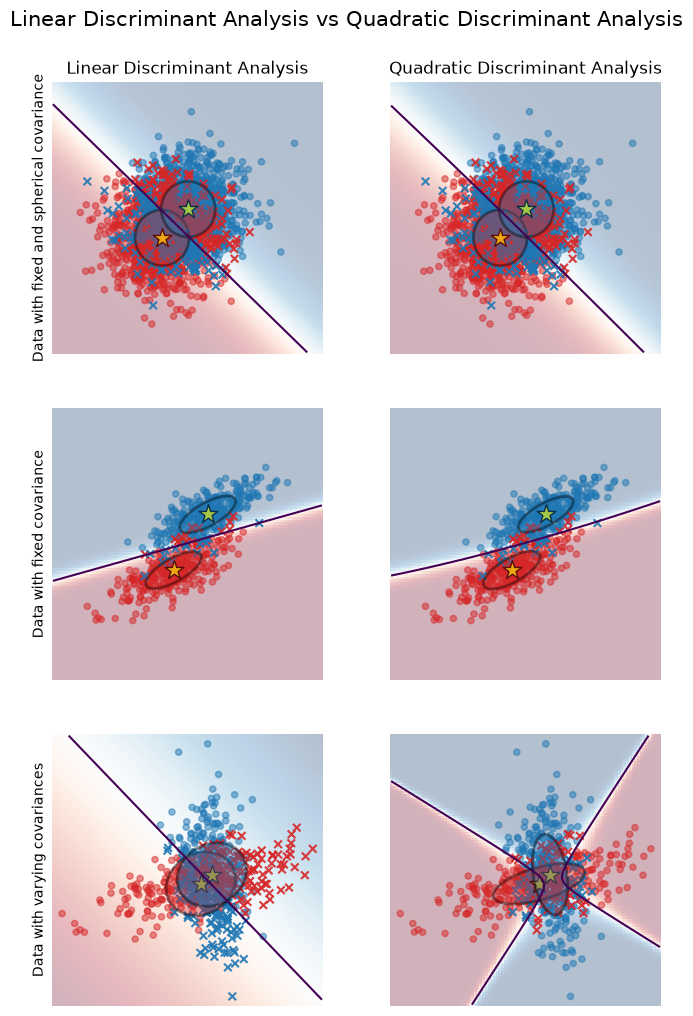

In [9]:
import matplotlib.pyplot as plt

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)

fig, axs = plt.subplots(nrows=3, ncols=2, sharex="row", sharey="row", figsize=(8, 12))

lda = LinearDiscriminantAnalysis(solver="svd", store_covariance=True)
qda = QuadraticDiscriminantAnalysis(solver="svd", store_covariance=True)

for ax_row, X, y in zip(
    axs,
    (X_isotropic_covariance, X_shared_covariance, X_different_covariance),
    (y_isotropic_covariance, y_shared_covariance, y_different_covariance),
):
    lda.fit(X, y)
    plot_result(lda, X, y, ax_row[0])
    qda.fit(X, y)
    plot_result(qda, X, y, ax_row[1])

axs[0, 0].set_title("Linear Discriminant Analysis")
axs[0, 0].set_ylabel("Data with fixed and spherical covariance")
axs[1, 0].set_ylabel("Data with fixed covariance")
axs[0, 1].set_title("Quadratic Discriminant Analysis")
axs[2, 0].set_ylabel("Data with varying covariances")
fig.suptitle(
    "Linear Discriminant Analysis vs Quadratic Discriminant Analysis",
    y=0.94,
    fontsize=15,
)
plt.show()

# Linear Discriminant Analysis (LDA) und Quadratic Discriminant Analysis (QDA)

## Ziel: Vergleich zweier Klassifikationsverfahren anhand ihrer Annahmen über die Kovarianz der Klassen.

- Es werden drei künstliche Datensätze mit jeweils zwei Klassen erzeugt.
- Datensatz 1: Beide Klassen haben dieselbe kreisförmige Kovarianz.
- Datensatz 2: Beide Klassen haben dieselbe, nicht kreisförmige Kovarianz.
- Datensatz 3: Beide Klassen haben unterschiedliche Kovarianzmatrizen.

## Visualisierung:
- Farbige Flächen zeigen die vom Modell vorhergesagten Klassen.
- Kreise stellen korrekt klassifizierte Datenpunkte dar.
- Kreuze markieren falsch klassifizierte Datenpunkte.
- Sterne kennzeichnen die geschätzten Mittelwerte der Klassen.
- Ellipsen veranschaulichen die geschätzte Kovarianz und Streuung der Klassen.

## Unterschied zwischen LDA und QDA:
- LDA geht davon aus, dass alle Klassen dieselbe Kovarianzmatrix besitzen. Dadurch entsteht eine lineare Entscheidungsgrenze.
- QDA schätzt für jede Klasse eine eigene Kovarianzmatrix. Dadurch kann eine gekrümmte Entscheidungsgrenze entstehen.

## Ergebnis:
- Bei gleichen Kovarianzmatrizen verhalten sich LDA und QDA ähnlich.
- Bei unterschiedlichen Kovarianzmatrizen werden die Unterschiede sichtbar. QDA kann sich besser an die unterschiedlichen Verteilungen anpassen.

## Key Takeaway:

Die Form der Entscheidungsgrenze hängt davon ab, welche Annahmen ein Modell über die Daten trifft.

# Normal, Ledoit-Wolf and OAS Linear Discriminant Analysis for classification

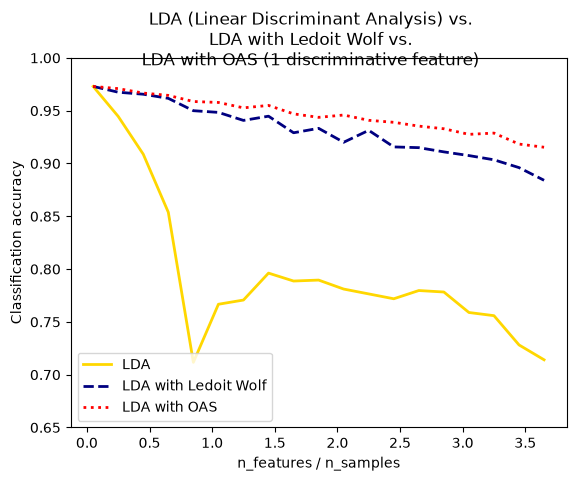

In [10]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import matplotlib.pyplot as plt
import numpy as np

from sklearn.covariance import OAS
from sklearn.datasets import make_blobs
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

n_train = 20  # samples for training
n_test = 200  # samples for testing
n_averages = 50  # how often to repeat classification
n_features_max = 75  # maximum number of features
step = 4  # step size for the calculation


def generate_data(n_samples, n_features):
    """Generate random blob-ish data with noisy features.

    This returns an array of input data with shape `(n_samples, n_features)`
    and an array of `n_samples` target labels.

    Only one feature contains discriminative information, the other features
    contain only noise.
    """
    X, y = make_blobs(n_samples=n_samples, n_features=1, centers=[[-2], [2]])

    # add non-discriminative features
    if n_features > 1:
        X = np.hstack([X, np.random.randn(n_samples, n_features - 1)])
    return X, y


acc_clf1, acc_clf2, acc_clf3 = [], [], []
n_features_range = range(1, n_features_max + 1, step)
for n_features in n_features_range:
    score_clf1, score_clf2, score_clf3 = 0, 0, 0
    for _ in range(n_averages):
        X, y = generate_data(n_train, n_features)

        clf1 = LinearDiscriminantAnalysis(solver="lsqr", shrinkage=None).fit(X, y)
        clf2 = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto").fit(X, y)
        oa = OAS(store_precision=False, assume_centered=False)
        clf3 = LinearDiscriminantAnalysis(solver="lsqr", covariance_estimator=oa).fit(
            X, y
        )

        X, y = generate_data(n_test, n_features)
        score_clf1 += clf1.score(X, y)
        score_clf2 += clf2.score(X, y)
        score_clf3 += clf3.score(X, y)

    acc_clf1.append(score_clf1 / n_averages)
    acc_clf2.append(score_clf2 / n_averages)
    acc_clf3.append(score_clf3 / n_averages)

features_samples_ratio = np.array(n_features_range) / n_train

plt.plot(
    features_samples_ratio,
    acc_clf1,
    linewidth=2,
    label="LDA",
    color="gold",
    linestyle="solid",
)
plt.plot(
    features_samples_ratio,
    acc_clf2,
    linewidth=2,
    label="LDA with Ledoit Wolf",
    color="navy",
    linestyle="dashed",
)
plt.plot(
    features_samples_ratio,
    acc_clf3,
    linewidth=2,
    label="LDA with OAS",
    color="red",
    linestyle="dotted",
)

plt.xlabel("n_features / n_samples")
plt.ylabel("Classification accuracy")

plt.legend(loc="lower left")
plt.ylim((0.65, 1.0))
plt.suptitle(
    "LDA (Linear Discriminant Analysis) vs."
    "\n"
    "LDA with Ledoit Wolf vs."
    "\n"
    "LDA with OAS (1 discriminative feature)"
)
plt.show()

# Vergleich verschiedener LDA-Varianten

### Ziel:
 Untersuchung, ob verbesserte Kovarianzschätzungen die Klassifikationsleistung von LDA verbessern können.

- Vergleich von drei Varianten: normales LDA, LDA mit Ledoit-Wolf und LDA mit OAS.
- Es werden künstliche Datensätze mit unterschiedlich vielen Merkmalen erzeugt.
- Es stehen nur 20 Trainingsdatenpunkte und 200 Testdatenpunkte zur Verfügung.
- Nur ein Merkmal enthält tatsächlich Informationen zur Unterscheidung der Klassen; die übrigen enthalten hauptsächlich Rauschen.
- Jeder Versuch wird 50-mal wiederholt.

### Visualisierung:
- X-Achse: Verhältnis zwischen Anzahl der Features und Anzahl der Trainingsdaten.
- Y-Achse: Classification Accuracy.
- Drei Linien zeigen die durchschnittliche Accuracy der jeweiligen LDA-Variante.

### Ergebnis: 
Ledoit-Wolf und OAS können durch stabilere Kovarianzschätzungen die Klassifikationsleistung verbessern, insbesondere wenn viele Features und nur wenige Trainingsdaten vorhanden sind.

### Key Takeaway
Eine verbesserte Schätzung der Kovarianzmatrix kann die Klassifikationsleistung stabilisieren, besonders bei wenigen Trainingsdaten und vielen Features.

### Relevanz für unser Projekt
Geringe Relevanz. Das Beispiel beschäftigt sich hauptsächlich mit der Verbesserung eines bestimmten Klassifikationsverfahrens und nicht direkt mit Active Learning oder Unsicherheitsvisualisierung.

# Plot classification probability

In [25]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import cm

from sklearn import datasets
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    KBinsDiscretizer,
    PolynomialFeatures,
    SplineTransformer,
)

numpy: Verarbeitung von Zahlen und Daten.

pandas: Verarbeitung tabellarischer Daten.

matplotlib: Erstellung von Grafiken.

datasets: Zugriff auf vorgefertigte Datensätze.

LogisticRegression: Ein Klassifikationsverfahren.

train_test_split: Aufteilung der Daten in Trainings- und Testdaten.

accuracy_score: Berechnung der Genauigkeit eines Modells.

DecisionBoundaryDisplay: Visualisierung der Entscheidungsgrenzen eines Modells.

Data: 2D projection of the iris dataset

In [26]:
iris = datasets.load_iris()
X = iris.data[:, 0:2]  # we only take the first two features for visualization
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42
)

#### Zeile 1: 
Lädt den Iris-Datensatz aus scikit-learn.
Der Datensatz enthält Messwerte von 150 Blumen.
Jede Blume gehört zu einer von drei Arten.
#### Zeile 2: 
X enthält die Merkmale (Features), anhand derer das Modell lernt.
Hier werden nur die ersten beiden Merkmale verwendet:
- Länge des Kelchblatts (sepal length).
- Breite des Kelchblatts (sepal width).
Die anderen beiden Merkmale werden weggelassen, damit die Daten zweidimensional dargestellt werden können.
#### Zeile 3:
y enthält die tatsächlichen Klassen der Blumen.
Es gibt drei mögliche Klassen: 0, 1 und 2.
#### Zeile 4:
50 % der Daten werden zum Trainieren verwendet.
50 % werden zum Testen verwendet.
random_state=42 sorgt dafür, dass die Aufteilung bei erneuter Ausführung gleich bleibt.

Probabilistic classifiers

In [27]:
classifiers = {
    "Logistic regression\n(C=0.1)": LogisticRegression(C=0.1),
    "Logistic regression\n(C=100)": LogisticRegression(C=100),
    "Gaussian Process": GaussianProcessClassifier(kernel=1.0 * RBF([1.0, 1.0])),
    "Logistic regression\n(RBF features)": make_pipeline(
        Nystroem(kernel="rbf", gamma=5e-1, n_components=50, random_state=1),
        LogisticRegression(C=10),
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "Logistic regression\n(binned features)": make_pipeline(
        KBinsDiscretizer(n_bins=5, quantile_method="averaged_inverted_cdf"),
        PolynomialFeatures(interaction_only=True),
        LogisticRegression(C=10),
    ),
    "Logistic regression\n(spline features)": make_pipeline(
        SplineTransformer(n_knots=5),
        PolynomialFeatures(interaction_only=True),
        LogisticRegression(C=10),
    ),
}

### Was passiert hier?
Hier werden sieben verschiedene Klassifikationsmodelle definiert.

Ein Klassifikationsmodell versucht, Datenpunkten eine Klasse zuzuordnen.

Beispiele:
- Logistic Regression: Berechnet Wahrscheinlichkeiten für die Zugehörigkeit zu einer Klasse.
- Gaussian Process: Ein probabilistisches Modell, das Vorhersagen inklusive Unsicherheit ermöglicht.
- Gradient Boosting: Kombiniert mehrere Entscheidungsbäume, um Vorhersagen zu verbessern.
Die verschiedenen Varianten der Logistic Regression verwenden unterschiedliche Einstellungen oder Transformationen der Eingabedaten.

### Was ist C?

C ist ein Parameter der Logistic Regression, der die Stärke der Regularisierung beeinflusst.

Du musst die mathematischen Details dazu momentan nicht kennen.

Wichtig für unser Projekt: Wir haben hier mehrere Modelle, die wir später hinsichtlich ihrer Vorhersagen und Unsicherheit vergleichen können.

Plotting the decision boundaries

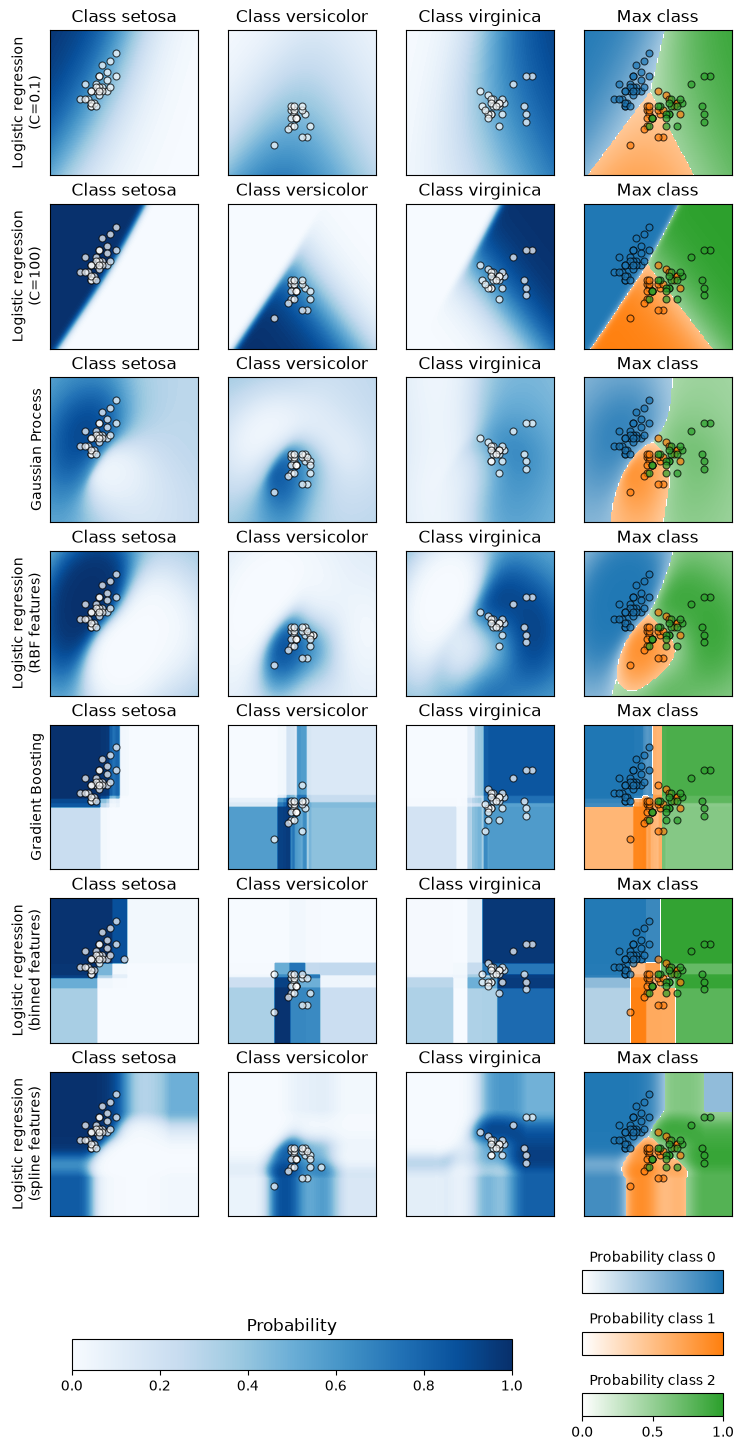

In [28]:
n_classifiers = len(classifiers)
scatter_kwargs = {
    "s": 25,
    "marker": "o",
    "linewidths": 0.8,
    "edgecolor": "k",
    "alpha": 0.7,
}
y_unique = np.unique(y)

# Ensure legend not cut off
mpl.rcParams["savefig.bbox"] = "tight"
fig, axes = plt.subplots(
    nrows=n_classifiers,
    ncols=len(iris.target_names) + 1,
    figsize=(4 * 2.2, n_classifiers * 2.2),
)
evaluation_results = []
levels = 100
for classifier_idx, (name, classifier) in enumerate(classifiers.items()):
    y_pred = classifier.fit(X_train, y_train).predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test)
    accuracy_test = accuracy_score(y_test, y_pred)
    roc_auc_test = roc_auc_score(y_test, y_pred_proba, multi_class="ovr")
    log_loss_test = log_loss(y_test, y_pred_proba)
    evaluation_results.append(
        {
            "name": name.replace("\n", " "),
            "accuracy": accuracy_test,
            "roc_auc": roc_auc_test,
            "log_loss": log_loss_test,
        }
    )
    for label in y_unique:
        # plot the probability estimate provided by the classifier
        disp = DecisionBoundaryDisplay.from_estimator(
            classifier,
            X_train,
            response_method="predict_proba",
            class_of_interest=label,
            ax=axes[classifier_idx, label],
            vmin=0,
            vmax=1,
            cmap="Blues",
            levels=levels,
        )
        axes[classifier_idx, label].set_title(f"Class {iris.target_names[label]}")
        # plot data predicted to belong to given class
        mask_y_pred = y_pred == label
        axes[classifier_idx, label].scatter(
            X_test[mask_y_pred, 0], X_test[mask_y_pred, 1], c="w", **scatter_kwargs
        )

        axes[classifier_idx, label].set(xticks=(), yticks=())
    # add column that shows all classes by plotting class with max 'predict_proba'
    max_class_disp = DecisionBoundaryDisplay.from_estimator(
        classifier,
        X_train,
        response_method="predict_proba",
        class_of_interest=None,
        ax=axes[classifier_idx, len(y_unique)],
        vmin=0,
        vmax=1,
        levels=levels,
    )
    for label in y_unique:
        mask_label = y_test == label
        max_col = len(y_unique)
        axes[classifier_idx, max_col].scatter(
            X_test[mask_label, 0],
            X_test[mask_label, 1],
            c=max_class_disp.multiclass_colors_[[label], :],
            **scatter_kwargs,
        )

    axes[classifier_idx, 3].set(xticks=(), yticks=())
    axes[classifier_idx, 3].set_title("Max class")
    axes[classifier_idx, 0].set_ylabel(name)

# colorbar for single class plots
ax_single = fig.add_axes([0.15, 0.01, 0.5, 0.02])
plt.title("Probability")
_ = plt.colorbar(
    cm.ScalarMappable(norm=None, cmap=disp.surface_.cmap),
    cax=ax_single,
    orientation="horizontal",
)

# colorbars for max probability class column
max_class_cmaps = [s.cmap for s in max_class_disp.surface_]

for label in y_unique:
    ax_max = fig.add_axes([0.73, (0.06 - (label * 0.04)), 0.16, 0.015])
    plt.title(f"Probability class {label}", fontsize=10)
    _ = plt.colorbar(
        cm.ScalarMappable(norm=None, cmap=max_class_cmaps[label]),
        cax=ax_max,
        orientation="horizontal",
    )
    if label in (0, 1):
        ax_max.set(xticks=(), yticks=())

# Plot classification probability

### Ziel des Beispiels

- Untersuchung verschiedener Klassifikationsmodelle anhand des Iris-Datensatzes.
- Vergleich der vorhergesagten Klassenwahrscheinlichkeiten verschiedener Modelle.
- Visualisierung der Bereiche, in denen ein Modell eine bestimmte Klasse bevorzugt.

### Datengrundlage

- Datensatz: Iris-Datensatz.
- Enthält drei Iris-Arten:
  - Setosa
  - Versicolor
  - Virginica
- Für die Visualisierung werden zwei Merkmale verwendet:
  - Sepal length: Kelchblattlänge
  - Sepal width: Kelchblattbreite
- Die beiden Merkmale bilden die x- und y-Achse des Diagramms.
- Jeder dargestellte Punkt entspricht einer Blume mit einer bestimmten Kombination dieser beiden Merkmale.

### Untersuchte Klassifikationsmodelle

Folgende Modelle werden miteinander verglichen:

- Logistic Regression (C = 0.1)
- Logistic Regression (C = 100)
- Gaussian Process
- Logistic Regression mit RBF-Features
- Gradient Boosting
- Logistic Regression mit Binned Features
- Logistic Regression mit Spline Features

### Erklärung der Visualisierung

Die Abbildung besteht aus mehreren Zeilen und vier Spalten.

**Zeilen:**
- Jede Zeile zeigt ein anderes Klassifikationsmodell.
- Dadurch wird sichtbar, wie unterschiedlich die Modelle dieselben Daten klassifizieren.

**Erste drei Spalten – Klassenwahrscheinlichkeiten:**
- Jede Spalte zeigt die vorhergesagte Wahrscheinlichkeit für eine bestimmte Iris-Klasse.
- Class setosa: Wahrscheinlichkeit für Setosa.
- Class versicolor: Wahrscheinlichkeit für Versicolor.
- Class virginica: Wahrscheinlichkeit für Virginica.
- Die Farbintensität zeigt die Höhe der vorhergesagten Wahrscheinlichkeit.
- Dunklere Farben stehen für höhere Wahrscheinlichkeiten, hellere Farben für niedrigere Wahrscheinlichkeiten.
- Die Wahrscheinlichkeiten liegen zwischen 0 und 1.

**Vierte Spalte – Max class:**
- Zeigt die Klasse mit der höchsten vorhergesagten Wahrscheinlichkeit.
- Jeder Bereich wird entsprechend der bevorzugten Klasse eingefärbt.
- Die Farben unterscheiden die drei vorhergesagten Klassen.

**Datenpunkte:**
- Die Kreise stellen die dargestellten Testdaten dar.
- Ihre Position ergibt sich aus Kelchblattlänge und Kelchblattbreite.
- Die Punkte ermöglichen einen Vergleich zwischen den tatsächlichen Daten und den Vorhersagen des Modells.

### Bedeutung der Visualisierung

- Die farbigen Flächen zeigen die vorhergesagten Wahrscheinlichkeiten für viele mögliche Merkmalskombinationen.
- Die Wahrscheinlichkeiten werden nicht nur an den Positionen der sichtbaren Datenpunkte berechnet, sondern auch für zusätzliche Punkte in einem Raster.
- Dadurch wird die gesamte Vorhersagefläche des Modells sichtbar.
- Bereiche mit hohen Wahrscheinlichkeiten zeigen, wo das Modell eine Klasse bevorzugt.
- Übergangsbereiche zwischen den Klassen können auf mehrdeutige Vorhersagen hinweisen.
- Die unterschiedlichen Formen der Flächen zeigen, wie stark die Vorhersagen von der Wahl des Klassifikationsmodells abhängen.

### Beobachtungen

- Logistic Regression mit C = 0.1 zeigt eher weiche Übergänge zwischen den Klassen.
- Logistic Regression mit C = 100 erzeugt deutlich stärkere Abgrenzungen.
- Gaussian Process erzeugt eher abgerundete und lokale Wahrscheinlichkeitsbereiche.
- Gradient Boosting zeigt auffällig rechteckige Bereiche.
- Die Varianten mit RBF-, Binned- und Spline-Features erzeugen jeweils unterschiedliche Formen der Vorhersageflächen.

### Einschränkung der Interpretation

- Die dargestellten Werte sind vorhergesagte Klassenwahrscheinlichkeiten.
- Eine hohe Klassenwahrscheinlichkeit bedeutet nicht automatisch, dass das Modell an dieser Stelle besonders viel gelernt hat oder besonders sicher im Sinne epistemischer Unsicherheit ist.
- Die Visualisierung zeigt keine direkte Trennung zwischen epistemischer und aleatorischer Unsicherheit.
- Ähnliche Wahrscheinlichkeiten für mehrere Klassen können auf eine mehrdeutige Klassenvorhersage hinweisen.

#### Zeile 20 (hier passiert die eigentliche Classification):
Geht nacheinander alle sieben Klassifikationsmodelle durch.
name enthält den Namen des Modells.
classifier enthält das jeweilige Modell.

#### Zeile 21:
fit()
- Trainiert das Modell mit den Trainingsdaten.
- Das Modell lernt Zusammenhänge zwischen den Merkmalen und den Klassen.
predict()
- Sagt die Klasse für jeden Testdatenpunkt voraus.
predict_proba()
- Berechnet die vorhergesagten Wahrscheinlichkeiten für jede Klasse.
Das ist besonders wichtig!

#### Zeile 23-25:
Hier werden drei Bewertungsmaße berechnet:
- Accuracy: Wie viele Vorhersagen waren richtig?
- ROC-AUC: Wie gut kann das Modell die Klassen unterscheiden?
- Log Loss: Wie gut sind die vorhergesagten Wahrscheinlichkeiten?
Für unser erstes Experiment reicht es, wenn du zunächst die Accuracy verstehst.

#### Zeile 36-46:
Das ist der zentrale Teil der Visualisierung.
- classifier: Das trainierte Modell.
- X_train: Die verwendeten Trainingsdaten.
- predict_proba: Es werden Wahrscheinlichkeiten statt nur Klassen vorhergesagt.
- class_of_interest: Für welche Klasse die Wahrscheinlichkeit dargestellt werden soll.
- cmap="Blues": Verwendet eine Blautönung für die Darstellung.
- vmin=0, vmax=1: Die Wahrscheinlichkeiten reichen von 0 bis 1.
Die Farbe zeigt also, wie wahrscheinlich die Zugehörigkeit zu einer bestimmten Klasse ist.

In [18]:
import probly

print("Probly wurde erfolgreich importiert!")

Probly wurde erfolgreich importiert!


Probly Methoden importieren

In [29]:
from probly.evaluation.active_learning import (
    from_dataset,
    RandomQuery,
    MarginSampling,
    active_learning_steps,
    compute_accuracy,
    compute_nauc
)

Was importieren wir? (Funktionen)
from_dataset: Erstellt unseren Active-Learning-Datenpool.
RandomQuery:	Zufällige Auswahl von Datenpunkten.
MarginSampling:	Auswahl anhand der Klassenwahrscheinlichkeiten.
active_learning_steps:	Führt den Active-Learning-Prozess durch.
compute_accuracy:	Berechnet die Klassifikationsgenauigkeit.
compute_nauc:	Bewertet, wie schnell sich die Accuracy verbessert.

2. Active learning vorbereiten

In [30]:
# Einstellungen
INITIAL_SIZE = 30
QUERY_SIZE = 5
N_ITERATIONS = 8
SEED = 42

# Auswahlstrategien
strategies = {
    "Random Sampling": RandomQuery(seed=SEED),
    "Margin Sampling": MarginSampling()
}

Was bedeuten die Einstellungen?
- INITIAL_SIZE = 30: Das Modell startet mit 30 gelabelten Trainingsdaten.
- QUERY_SIZE = 5: Pro Durchlauf werden fünf neue Datenpunkte ausgewählt.
- N_ITERATIONS = 8: Der Auswahl- und Trainingsprozess wird achtmal wiederholt.
- SEED = 42: Sorgt für reproduzierbare Zufallsergebnisse.

3. Active Learning durchführen

In [31]:
results = {}

for name, strategy in strategies.items():

    # Active-Learning-Datenpool erstellen
    pool = from_dataset(
        X_train,
        y_train,
        X_test,
        y_test,
        initial_size=INITIAL_SIZE,
        seed=SEED
    )

    # Klassifikationsmodell erstellen
    model = LogisticRegression(
        C=0.1,
        max_iter=1000,
        random_state=SEED
    )

    accuracies = []
    labeled_sizes = []

    # Active Learning durchführen
    for state in active_learning_steps(
        pool,
        model,
        strategy,
        query_size=QUERY_SIZE,
        n_iterations=N_ITERATIONS
    ):

        predictions = state.estimator.predict(state.pool.x_test)

        accuracy = compute_accuracy(
            predictions,
            state.pool.y_test
        )

        accuracies.append(accuracy)
        labeled_sizes.append(state.pool.n_labeled)

    results[name] = {
        "accuracies": accuracies,
        "labeled_sizes": labeled_sizes
    }

    print(
        f"{name}: "
        f"Final Accuracy = {accuracies[-1]:.3f}"
    )

Random Sampling: Final Accuracy = 0.827
Margin Sampling: Final Accuracy = 0.840


Was passiert hier?
Der Code führt zwei getrennte Experimente durch.

Experiment 1: Random Sampling

Probly wählt zufällig fünf neue Datenpunkte aus. Anschließend werden diese zum Trainingsdatensatz hinzugefügt und das Modell wird erneut trainiert.

Experiment 2: Margin Sampling

Probly untersucht die vorhergesagten Klassenwahrscheinlichkeiten und wählt fünf besonders unentschlossene Datenpunkte aus.

Anschließend wird auch hier das Modell erneut trainiert.

Beide Experimente starten mit denselben Ausgangsbedingungen.

4. Ergebnisse visualisieren

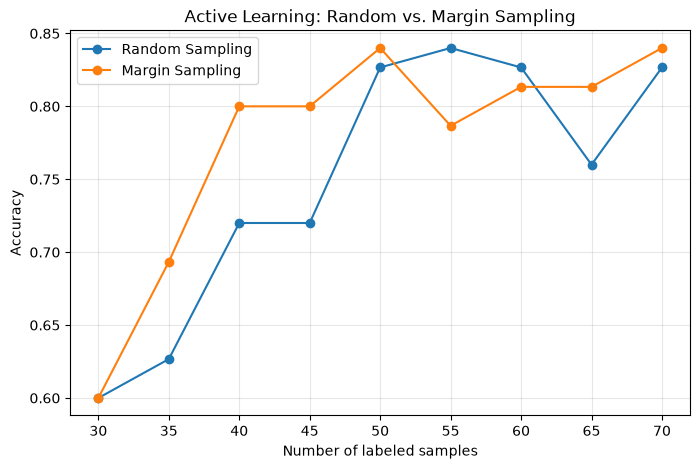

In [32]:
plt.figure(figsize=(8, 5))

for name, data in results.items():
    plt.plot(
        data["labeled_sizes"],
        data["accuracies"],
        marker="o",
        label=name
    )

plt.xlabel("Number of labeled samples")
plt.ylabel("Accuracy")
plt.title("Active Learning: Random vs. Margin Sampling")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Wie interpretieren wir die Grafik?
- X-Achse: Anzahl der gelabelten Datenpunkte.
- Y-Achse: Accuracy des Klassifikationsmodells.
- Eine höhere Linie bedeutet eine bessere Klassifikationsleistung.
- Eine schneller steigende Linie deutet darauf hin, dass die Auswahlstrategie effizienter lernt.

Unsicherheitsquantifizierung mit Probly

### Uncertainty Quantification – First-Order Representation

Im ersten Schritt werden die vom Klassifikationsmodell vorhergesagten Klassenwahrscheinlichkeiten untersucht.

Die Funktion `predict_proba()` liefert für jeden Datenpunkt eine Wahrscheinlichkeitsverteilung über die möglichen Klassen.

Probly kann diese Verteilung verwenden, um die Gesamtunsicherheit (Total Uncertainty) mithilfe der Entropie zu quantifizieren.

Eine einzelne Wahrscheinlichkeitsverteilung ermöglicht allerdings noch keine getrennte Berechnung der aleatorischen und epistemischen Unsicherheit.

In [33]:
from probly.representation.distribution import create_categorical_distribution
from probly.quantification import quantify

# Wahrscheinlichkeiten des bereits trainierten Modells
probabilities = classifier.predict_proba(X_test)

# Wahrscheinlichkeiten als Probly-Repräsentation
representation = create_categorical_distribution(probabilities)

# Unsicherheit quantifizieren
uncertainty = quantify(representation)

print("Total Uncertainty:")
print(uncertainty.total)

Total Uncertainty:
[0.70430638 0.49940789 0.27894076 0.70454512 0.69774676 0.53658316
 0.59499389 0.6385254  0.7327509  0.61710769 0.61834699 0.40752563
 0.54709514 0.3190508  0.06502932 0.54792812 0.71065123 0.42530786
 0.59532432 0.70694825 0.09179204 0.7338547  0.10634734 0.70694825
 0.75377757 0.70086441 0.67804642 0.58588618 0.40752563 0.21920223
 0.03023834 0.48199821 0.67772208 0.05538737 0.06884902 0.67437268
 0.63505946 0.17031803 0.06061882 0.11685012 0.61710769 0.74939632
 0.67772208 0.18801765 0.21861415 0.35421852 0.70759941 0.70453614
 0.70656162 0.4746961  0.61513852 0.30606114 0.66908712 0.11319638
 0.22365217 0.61710769 0.2452032  0.07750726 0.06502932 0.80002697
 0.70314107 0.05538737 0.75063949 0.24915734 0.53839468 0.16023751
 0.67138012 0.75377757 0.07535712 0.71515512 0.47444787 0.28905936
 0.73184704 0.61710769 0.71870477]


Was passiert hier?
1. predict_proba() holt die Wahrscheinlichkeiten des Modells.
2. create_categorical_distribution() übergibt diese an Probly als Wahrscheinlichkeitsverteilung.
3. quantify() berechnet daraus die entsprechende Unsicherheitsquantifizierung.
4. uncertainty.total enthält die Gesamtunsicherheit für die einzelnen Testdatenpunkte.
Die Entropie beschreibt dabei, wie gleichmäßig die Wahrscheinlichkeiten auf die drei Klassen verteilt sind. Je gleichmäßiger sie verteilt sind, desto höher ist die Entropie.

In [24]:
print("X_test shape:", X_test.shape)
print("Classifier:", classifier)
print("Erwartete Features:", classifier.n_features_in_)

X_test shape: (899, 64)
Classifier: Pipeline(steps=[('splinetransformer', SplineTransformer()),
                ('polynomialfeatures',
                 PolynomialFeatures(interaction_only=True)),
                ('logisticregression', LogisticRegression(C=10))])
Erwartete Features: 2


2. Warum brauchen wir jetzt eine Second-Order Representation?

Bisher (First-Order):

Das Modell gibt für einen Datenpunkt eine Wahrscheinlichkeitsverteilung aus.
![Beispiel](image.png)

Jetzt (Second-Order):

Statt nur einer Verteilung betrachten wir mehrere mögliche Vorhersageverteilungen für denselben Datenpunkt.
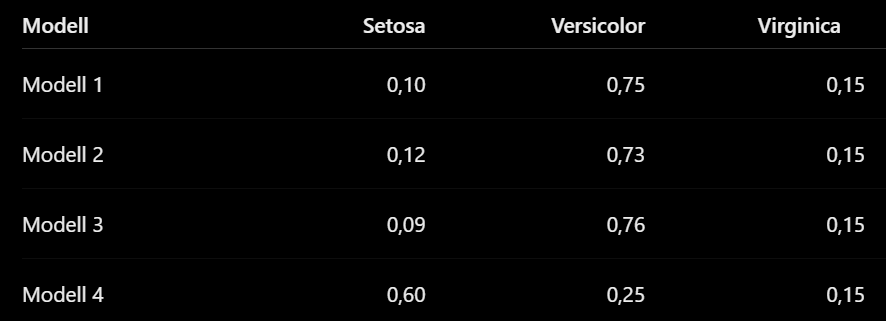

Hier unterscheiden sich die Modelle deutlich voneinander.

Diese Unterschiede helfen dabei, die epistemische Unsicherheit zu bestimmen.

Probly kann anschließend die Gesamtunsicherheit in zwei aleatorische und epistemische Unsicherheiten zerlegen

Wie setzen wir das mit deinem Iris-Beispiel um?

Wir benötigen mehrere Klassifikationsmodelle, die unterschiedliche Vorhersagen erzeugen.

Eine Möglichkeit ist ein sogenanntes Ensemble (aus mehreren Logistic-Regression-Modellen):
- Mehrere Modelle derselben Modellart werden trainiert.
- Jedes Modell erhält eine leicht unterschiedliche Trainingsgrundlage.
- Alle Modelle sagen anschließend dieselben Testdaten vorher.
- Probly fasst diese Vorhersagen zu einer Second-Order Representation zusammen.
Das entspricht dem in der offiziellen Probly-Dokumentation beschriebenen Ensemble-Prinzip
Und das ist eine geeignete Möglichkeit, die beiden Unsicherheitsarten zu untersuchen.

Schritt 1: Fünf Modelle trainieren

In [34]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample

# Anzahl der Modelle im Ensemble
N_MODELS = 5

ensemble_models = []

for i in range(N_MODELS):

    # Unterschiedliche Trainingsstichprobe erstellen
    X_sample, y_sample = resample(
        X_train,
        y_train,
        replace=True,
        random_state=42 + i
    )

    # Modell trainieren
    model = LogisticRegression(
        C=0.1,
        max_iter=1000,
        random_state=42 + i
    )

    model.fit(X_sample, y_sample)

    ensemble_models.append(model)

print("Anzahl trainierter Modelle:", len(ensemble_models))

Anzahl trainierter Modelle: 5


In [ ]:
Was passiert hier?
Wir trainieren fünf Logistic-Regression-Modelle.

resample() zieht für jedes Modell eine etwas andere Trainingsstichprobe.

Dadurch können sich die Modelle später in ihren Vorhersagen unterscheiden.

Schritt 2: Vorhersagen sammeln
Jetzt sollen alle fünf Modelle dieselben Testdaten klassifizieren.

In [35]:
# Vorhersagen aller Modelle sammeln
ensemble_predictions = []

for model in ensemble_models:

    probabilities = model.predict_proba(X_test)

    ensemble_predictions.append(probabilities)

# In ein NumPy-Array umwandeln
ensemble_predictions = np.array(ensemble_predictions)

print("Shape:", ensemble_predictions.shape)

Shape: (5, 75, 3)


### Second-Order Representation

Eine Second-Order Representation beschreibt eine Verteilung über mehrere First-Order-Wahrscheinlichkeitsverteilungen.

Für die vorliegende Untersuchung werden fünf Logistic-Regression-Modelle verwendet. Jedes Modell wurde mit einer unterschiedlichen Trainingsstichprobe trainiert und erzeugt für dieselben Testdaten eine Wahrscheinlichkeitsverteilung über die drei Iris-Klassen.

Die fünf Vorhersageverteilungen werden mit Probly zu einer gemeinsamen Repräsentation zusammengefasst.

Dadurch können sowohl die Gesamtunsicherheit als auch die aleatorische und epistemische Unsicherheit untersucht werden.

In [36]:
from probly.representation.distribution import (
    create_categorical_distribution
)
from probly.representation.sample import create_sample

# Jede Modellvorhersage in eine Probly-Verteilung umwandeln
distributions = [
    create_categorical_distribution(prediction)
    for prediction in ensemble_predictions
]

# Second-Order Representation erstellen
second_order = create_sample(
    distributions,
    sample_axis=0
)

print("Anzahl der Verteilungen:", second_order.sample_size)
print("Mittlere Vorhersagen:")
print(second_order.sample_mean().probabilities)

Anzahl der Verteilungen: 5
Mittlere Vorhersagen:
[[0.18899382 0.37632826 0.43467792]
 [0.45102769 0.24202103 0.30695128]
 [0.01984528 0.21776827 0.76238645]
 [0.22270892 0.3676206  0.40967048]
 [0.08093323 0.31117343 0.60789334]
 [0.47508356 0.28220977 0.24270667]
 [0.32495948 0.37043177 0.30460876]
 [0.08541062 0.2709719  0.64361747]
 [0.11586056 0.44640277 0.43773667]
 [0.24281006 0.40181409 0.35537585]
 [0.15129347 0.29963698 0.54906955]
 [0.57694234 0.28913863 0.13391903]
 [0.46191781 0.27369236 0.26438983]
 [0.56833209 0.28393655 0.14773136]
 [0.64099978 0.19944625 0.15955396]
 [0.20218998 0.30217183 0.49563819]
 [0.13427964 0.32167736 0.544043  ]
 [0.26158536 0.4338764  0.30453824]
 [0.28214391 0.38742418 0.33043191]
 [0.13412439 0.35369526 0.51218035]
 [0.64247736 0.24428471 0.11323794]
 [0.21230007 0.3499529  0.43774704]
 [0.59719067 0.2467738  0.15603554]
 [0.13412439 0.35369526 0.51218035]
 [0.03076299 0.12718274 0.84205427]
 [0.10447597 0.30204536 0.59347868]
 [0.0761511  0.

„Mittlere Vorhersagen“ bedeutet: Probly bildet für jeden Testdatenpunkt den Durchschnitt der Wahrscheinlichkeiten aller fünf Modelle.

Beispiel: Wenn fünf Modelle für eine Klasse die Wahrscheinlichkeiten 0,6; 0,7; 0,5; 0,8 und 0,4 vorhersagen, beträgt der Mittelwert 0,6.

Dieser Mittelwert ist also die gemeinsame Vorhersage des Ensembles.

In [ ]:
Nächster Schritt: Unsicherheit aufteilen
Jetzt kommt der wichtigste Teil: Wir lassen Probly die Gesamtunsicherheit in ihre Bestandteile zerlegen.

In [37]:
from probly.quantification import quantify

# Unsicherheit der Second-Order Representation berechnen
uncertainty_result = quantify(second_order)

# Ergebnisse ausgeben
print("Total Uncertainty:")
print(uncertainty_result.total)

print("\nAleatoric Uncertainty:")
print(uncertainty_result.aleatoric)

print("\nEpistemic Uncertainty:")
print(uncertainty_result.epistemic)

Total Uncertainty:
[1.04480648 1.06501267 0.61657541 1.06795439 0.86932457 1.05426153
 1.09523955 0.84756385 0.97139178 1.0777166  0.97602417 0.94535002
 1.0631336  0.96112858 0.89945976 1.03273023 0.96563291 1.0751528
 1.09028194 0.9797455  0.87520931 1.05807739 0.94303223 0.9797455
 0.51412522 0.90724208 0.88434233 0.88324191 0.94535002 0.92887823
 0.74590797 0.98223305 0.91144469 0.87087602 0.76278299 0.98015083
 1.0033578  0.99034586 0.90399753 0.87225334 1.0777166  1.08632978
 0.91144469 0.98358288 1.01616388 1.06979914 1.00371102 0.99811098
 0.93711035 0.75187459 1.0944457  0.62835234 1.09645413 0.95862865
 0.60795383 1.0777166  1.00563675 0.92413013 0.89945976 1.02249766
 0.99630486 0.87087602 1.00366126 0.99151165 1.08814378 0.97581319
 1.09718197 0.57661262 0.83833127 1.03261119 1.06975242 0.95982879
 1.07372271 1.0777166  1.00375506]

Aleatoric Uncertainty:
[1.03815475 1.05783678 0.60728433 1.06136208 0.86195625 1.0469017
 1.08792877 0.84078421 0.96341776 1.07066341 0.9697318

Was zeigen deine Ergebnisse?
für jeden der 75 Testdatenpunkte drei Unsicherheitswerte:
- Total Uncertainty: gesamte Unsicherheit.
- Aleatoric Uncertainty: Unsicherheit innerhalb der einzelnen Modellvorhersagen.
- Epistemic Uncertainty: Unsicherheit aufgrund der Unterschiede zwischen den fünf Modellen.

Beobachtung:Die epistemischen Werte sind relativ klein (ungefähr 0,006–0,01). Das deutet darauf hin, dass sich die fünf Modelle bei vielen Datenpunkten sehr ähnlich sind.

Wichtig: Die Werte sind keine Wahrscheinlichkeiten. Deshalb können sie auch größer als 1 sein. Bei der Entropie mit natürlichem Logarithmus liegt der Maximalwert für drei Klassen bei ungefähr 1,099.

Jetzt überprüfen wir die Zerlegung
Eine wichtige Eigenschaft der verwendeten Entropiezerlegung lautet:
Total= Aleatoric + Epistemic
Wir überprüfen, ob das bei unseren Ergebnissen gilt.

In [38]:
# Durchschnittliche Unsicherheit berechnen
print("Mean Total:",
      np.mean(uncertainty_result.total))

print("Mean Aleatoric:",
      np.mean(uncertainty_result.aleatoric))

print("Mean Epistemic:",
      np.mean(uncertainty_result.epistemic))

# Zerlegung überprüfen
difference = (
    uncertainty_result.total
    - uncertainty_result.aleatoric
    - uncertainty_result.epistemic
)

print("\nMaximum deviation:",
      np.max(np.abs(difference)))

Mean Total: 0.9526403133386232
Mean Aleatoric: 0.9451339449843605
Mean Epistemic: 0.0075063683542626915

Maximum deviation: 3.41740524767431e-16


Rund 94,5% der Unsicherheit entfallen auf aleatorische Unsicherheit
Nur rund 0,8% enfallen auf die epistemische Unsicherheit

Visualisierung der Ergebnisse
Wir erstellen eine Grafik, die zeigt, wie sich die drei Unsicherheitswerte auf die 75 Testdatenpunkte verteilen.

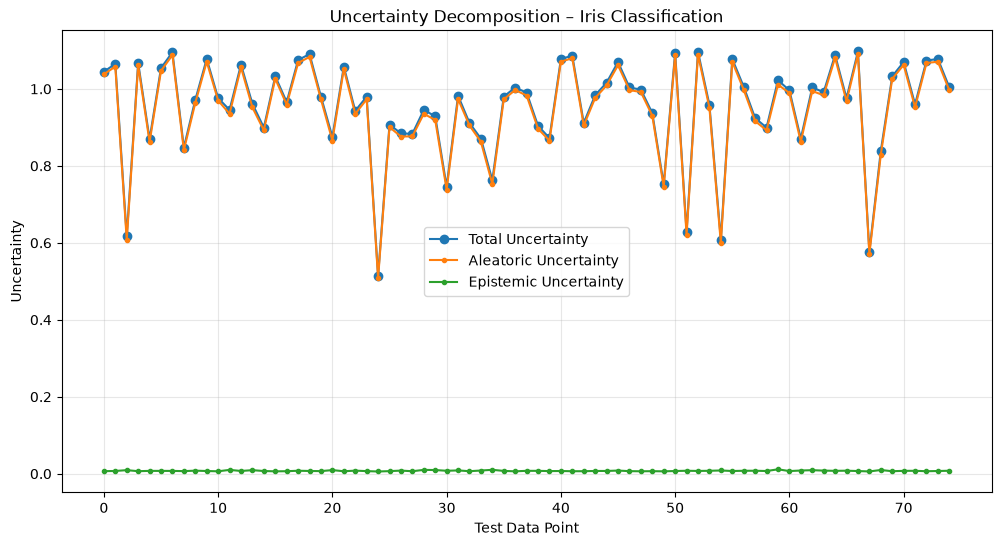

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    uncertainty_result.total,
    label="Total Uncertainty",
    marker="o"
)

plt.plot(
    uncertainty_result.aleatoric,
    label="Aleatoric Uncertainty",
    marker="."
)

plt.plot(
    uncertainty_result.epistemic,
    label="Epistemic Uncertainty",
    marker="."
)

plt.xlabel("Test Data Point")
plt.ylabel("Uncertainty")
plt.title("Uncertainty Decomposition – Iris Classification")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Interpretation
🔵 Total Uncertainty und 🟠 Aleatoric Uncertainty

Die beiden Kurven liegen fast vollständig übereinander. Das liegt daran, dass die aleatorische Unsicherheit mit durchschnittlich 0,9451 den größten Teil der Gesamtunsicherheit (0,9526) ausmacht.

🟢 Epistemic Uncertainty

Die grüne Kurve liegt fast auf der Nulllinie. Die epistemische Unsicherheit ist mit durchschnittlich 0,0075 sehr klein.

Das bedeutet: Unsere fünf Modelle liefern relativ ähnliche Vorhersagen. Die Unterschiede zwischen den Modellen tragen deshalb nur wenig zur Gesamtunsicherheit bei.

Die Ausschläge nach unten: An diesen Datenpunkten ist die Gesamtunsicherheit geringer. Das Modell verteilt seine Vorhersagewahrscheinlichkeiten dort weniger gleichmäßig auf die drei Klassen.
Wichtig für die Interpretation
Die X-Achse zeigt lediglich die Nummer des jeweiligen Testdatenpunkts. Sie zeigt keine zeitliche Entwicklung oder den Lernfortschritt des Modells.

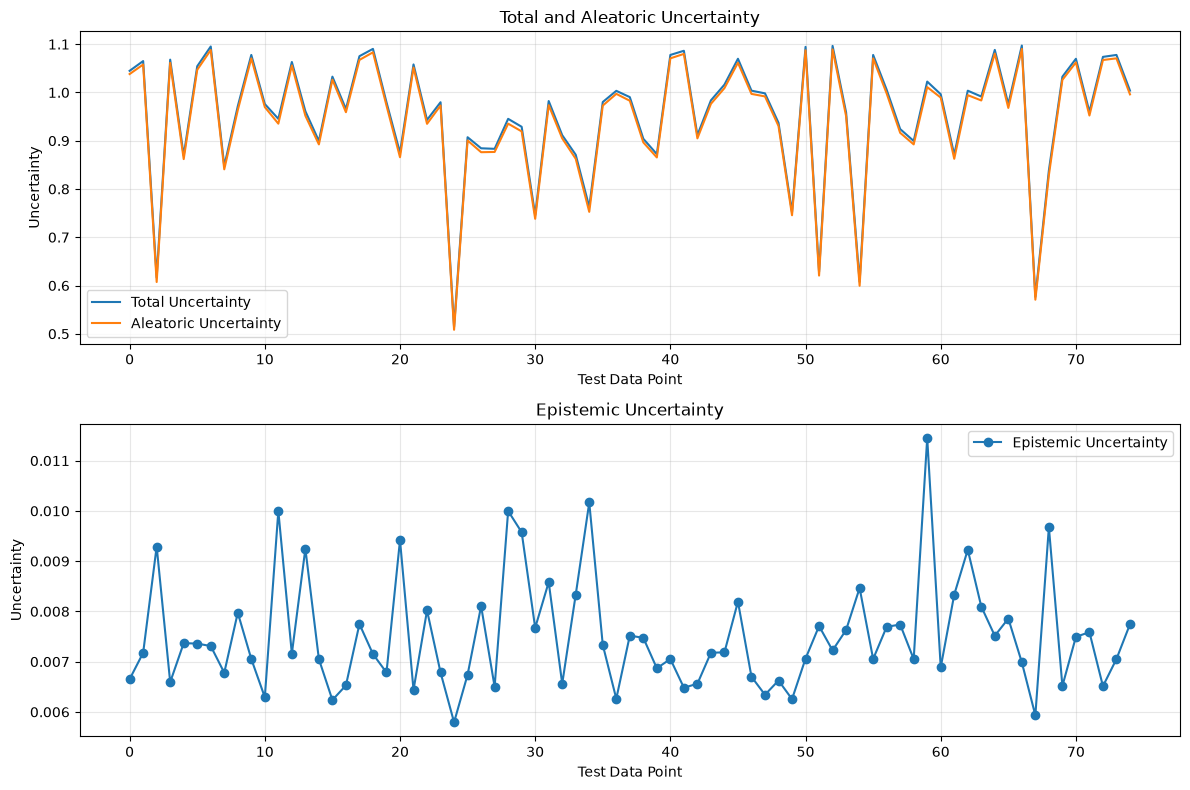

In [40]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Gesamt- und aleatorische Unsicherheit
axes[0].plot(
    uncertainty_result.total,
    label="Total Uncertainty"
)

axes[0].plot(
    uncertainty_result.aleatoric,
    label="Aleatoric Uncertainty"
)

axes[0].set_title("Total and Aleatoric Uncertainty")
axes[0].set_xlabel("Test Data Point")
axes[0].set_ylabel("Uncertainty")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Epistemische Unsicherheit separat
axes[1].plot(
    uncertainty_result.epistemic,
    label="Epistemic Uncertainty",
    marker="o"
)

axes[1].set_title("Epistemic Uncertainty")
axes[1].set_xlabel("Test Data Point")
axes[1].set_ylabel("Uncertainty")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Vergleich: Vorher und nachher mit Probly
Hier müssen wir einen wichtigen Unterschied verstehen:

Vor Probly:

Das normale Scikit-learn-Modell liefert mit predict_proba() lediglich Klassenwahrscheinlichkeiten.
Damit lässt sich erkennen, wie wahrscheinlich die einzelnen Klassen sind.

Nach Probly:

Durch die Second-Order Representation können zusätzlich drei Unsicherheitswerte untersucht werden:
- Total Uncertainty
- Aleatoric Uncertainty
- Epistemic Uncertainty
Probly liefert damit zusätzliche Informationen darüber, woher die Unsicherheit stammt.

Eine wichtige Anmerkung
Deine ursprüngliche First-Order-Berechnung verwendete einen anderen Klassifikator als unser Ensemble aus fünf Logistic-Regression-Modellen.

Deshalb sollten wir die damaligen Zahlen nicht direkt mit den jetzigen Mittelwerten vergleichen. Der qualitative Vergleich oben ist dagegen korrekt.

# Recognizing hand-written digits

In [11]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

# Standard scientific Python imports
import matplotlib.pyplot as plt

# Import datasets, classifiers and performance metrics
from sklearn import datasets, metrics, svm
from sklearn.model_selection import train_test_split

Digits dataset

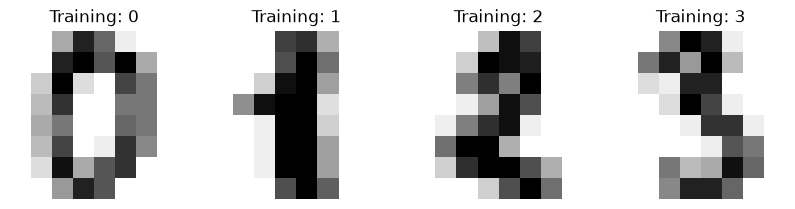

In [12]:
digits = datasets.load_digits()

_, axes = plt.subplots(nrows=1, ncols=4, figsize=(10, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)

Classification

In [13]:
# flatten the images
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Create a classifier: a support vector classifier
clf = svm.SVC(gamma=0.001)

# Split data into 50% train and 50% test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False
)

# Learn the digits on the train subset
clf.fit(X_train, y_train)

# Predict the value of the digit on the test subset
predicted = clf.predict(X_test)

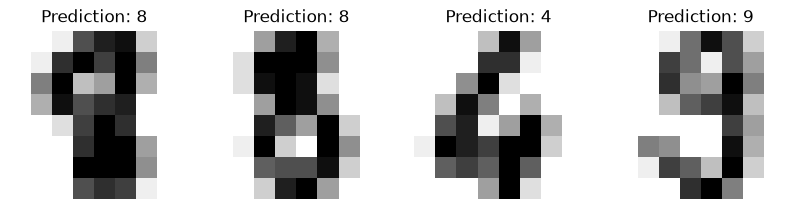

In [14]:
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(10, 3))
for ax, image, prediction in zip(axes, X_test, predicted):
    ax.set_axis_off()
    image = image.reshape(8, 8)
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Prediction: {prediction}")

In [15]:
print(
    f"Classification report for classifier {clf}:\n"
    f"{metrics.classification_report(y_test, predicted)}\n"
)

Classification report for classifier SVC(gamma=0.001):
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.99      0.97      0.98        91
           2       0.99      0.99      0.99        86
           3       0.98      0.87      0.92        91
           4       0.99      0.96      0.97        92
           5       0.95      0.97      0.96        91
           6       0.99      0.99      0.99        91
           7       0.96      0.99      0.97        89
           8       0.94      1.00      0.97        88
           9       0.93      0.98      0.95        92

    accuracy                           0.97       899
   macro avg       0.97      0.97      0.97       899
weighted avg       0.97      0.97      0.97       899




Confusion matrix:
[[87  0  0  0  1  0  0  0  0  0]
 [ 0 88  1  0  0  0  0  0  1  1]
 [ 0  0 85  1  0  0  0  0  0  0]
 [ 0  0  0 79  0  3  0  4  5  0]
 [ 0  0  0  0 88  0  0  0  0  4]
 [ 0  0  0  0  0 88  1  0  0  2]
 [ 0  1  0  0  0  0 90  0  0  0]
 [ 0  0  0  0  0  1  0 88  0  0]
 [ 0  0  0  0  0  0  0  0 88  0]
 [ 0  0  0  1  0  1  0  0  0 90]]


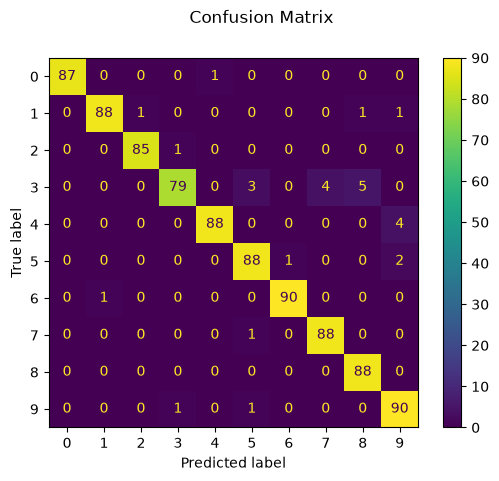

In [16]:
disp = metrics.ConfusionMatrixDisplay.from_predictions(y_test, predicted)
disp.figure_.suptitle("Confusion Matrix")
print(f"Confusion matrix:\n{disp.confusion_matrix}")

plt.show()

In [17]:
# The ground truth and predicted lists
y_true = []
y_pred = []
cm = disp.confusion_matrix

# For each cell in the confusion matrix, add the corresponding ground truths
# and predictions to the lists
for gt in range(len(cm)):
    for pred in range(len(cm)):
        y_true += [gt] * cm[gt][pred]
        y_pred += [pred] * cm[gt][pred]

print(
    "Classification report rebuilt from confusion matrix:\n"
    f"{metrics.classification_report(y_true, y_pred)}\n"
)

Classification report rebuilt from confusion matrix:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.99      0.97      0.98        91
           2       0.99      0.99      0.99        86
           3       0.98      0.87      0.92        91
           4       0.99      0.96      0.97        92
           5       0.95      0.97      0.96        91
           6       0.99      0.99      0.99        91
           7       0.96      0.99      0.97        89
           8       0.94      1.00      0.97        88
           9       0.93      0.98      0.95        92

    accuracy                           0.97       899
   macro avg       0.97      0.97      0.97       899
weighted avg       0.97      0.97      0.97       899




# Recognizing hand-written digits

### Ziel des Beispiels

- Automatische Erkennung handgeschriebener Ziffern von 0 bis 9.
- Klassifikation von kleinen Graustufenbildern mithilfe eines Support Vector Classifiers (SVC).
- Bewertung der Klassifikationsleistung anhand verschiedener Metriken und einer Confusion Matrix.

### Datengrundlage

- Datensatz: Digits-Datensatz von scikit-learn.
- Enthält handgeschriebene Ziffern von 0 bis 9.
- Jedes Bild besteht aus 8 × 8 Pixeln.
- Die Pixelwerte enthalten Informationen über die Helligkeit.
- Jedes Bild wird in einen Vektor mit 64 Merkmalen umgewandelt.
- Aufteilung in 50 % Trainingsdaten und 50 % Testdaten.

### Klassifikationsmodell

- Verwendet wird ein Support Vector Classifier (SVC).
- Das Modell wird mit den Trainingsdaten trainiert.
- Anschließend werden die Ziffern der Testdaten vorhergesagt.
- Die vorhergesagten Ziffern werden mit den tatsächlichen Ziffern verglichen.

### Erklärung der Visualisierungen

**1. Trainingsbilder**
- Darstellung der ersten vier Trainingsbilder.
- Jedes Bild zeigt eine handgeschriebene Ziffer.
- Der Titel gibt die tatsächliche Ziffer an.
- Die Graustufen repräsentieren die Helligkeitswerte der einzelnen Pixel.

**2. Testbilder und Vorhersagen**
- Darstellung der ersten vier Testbilder.
- Der Titel zeigt die vom Modell vorhergesagte Ziffer.
- Vergleich zwischen Bildinhalt und Vorhersage ermöglicht eine direkte Überprüfung der Klassifikation.

**3. Classification Report**
- Zusammenfassung der Klassifikationsleistung.
- Enthält folgende Kennzahlen:
  - Precision: Anteil der korrekten Vorhersagen unter allen Vorhersagen einer Klasse.
  - Recall: Anteil der korrekt erkannten Beispiele einer Klasse.
  - F1-Score: Kombiniert Precision und Recall.
  - Support: Anzahl der tatsächlichen Beispiele einer Klasse.
- Accuracy: Anteil aller korrekt klassifizierten Testbilder.

**4. Confusion Matrix**
- Zeilen: tatsächliche Ziffern.
- Spalten: vorhergesagte Ziffern.
- Diagonale: korrekt klassifizierte Bilder.
- Werte außerhalb der Diagonale: Fehlklassifikationen.
- Zeigt, welche Ziffern besonders häufig miteinander verwechselt werden.

### Bedeutung der Visualisierung

- Die Confusion Matrix ermöglicht eine detaillierte Untersuchung der Klassifikationsfehler.
- Neben der Gesamtgenauigkeit wird sichtbar, bei welchen Ziffern das Modell Schwierigkeiten hat.
- Häufige Verwechslungen zwischen bestimmten Ziffern können auf ähnliche Bildmuster hinweisen.
- Die Visualisierung ermöglicht eine differenzierte Bewertung der Klassifikationsleistung.

### Einschränkung im Hinblick auf Unsicherheit

- Das Beispiel verwendet die vorhergesagten Klassenlabels des SVC-Modells.
- Es werden keine Klassenwahrscheinlichkeiten oder eine direkte Messung epistemischer bzw. aleatorischer Unsicherheit dargestellt.
- Die Confusion Matrix zeigt Klassifikationsfehler, aber nicht, wie unsicher das Modell bei einer einzelnen Vorhersage war.

# Paper: Epistemic Uncertainty Sampling

**Forschungsfrage:**
Kann epistemische Unsicherheit dabei helfen, informativere Datenpunkte für das Active Learning auszuwählen?

### Schlüsselbegriffe

- Active Learning
- Uncertainty Sampling
- Epistemische Unsicherheit
- Aleatorische Unsicherheit
- Klassifikation

### 1. Grundidee

Beim Uncertainty Sampling werden Datenpunkte ausgewählt, bei denen das Modell besonders unsicher ist.

Das Paper unterscheidet zwei Ursachen dieser Unsicherheit:

**Epistemische Unsicherheit (Epistemic Uncertainty)**
- Entsteht durch fehlendes Wissen des Modells.
- Kann durch zusätzliche Trainingsdaten reduziert werden.
- Besonders interessant für Active Learning.

**Aleatorische Unsicherheit (Aleatoric Uncertainty)**
- Entsteht durch Zufälligkeit oder Mehrdeutigkeit in den Daten.
- Kann auch bei vielen Trainingsdaten bestehen bleiben.
- Lässt sich nicht grundsätzlich durch zusätzliche Labels beseitigen.

**Zentrale Idee:** Für Active Learning ist epistemische Unsicherheit besonders interessant, weil das Modell durch zusätzliche beschriftete Daten neues Wissen gewinnen kann.

### 2. Vorgeschlagene Methode

Die Autoren entwickeln zwei Maße, um die beiden Unsicherheitsarten getrennt zu erfassen.

**Epistemische Unsicherheit:**

u_e(x) = min(π(1|x), π(0|x))

**Aleatorische Unsicherheit:**

u_a(x) = 1 - max(π(1|x), π(0|x))

Dabei stehen π(1|x) und π(0|x) für die Unterstützung der beiden möglichen Klassen.

**Auswahlstrategie:**

- Das Modell betrachtet die noch unbeschrifteten Datenpunkte.
- Es wählt den Datenpunkt mit der höchsten epistemischen Unsicherheit aus.
- Das Label wird abgefragt.
- Der neue Datenpunkt wird zum Trainingsdatensatz hinzugefügt.
- Das Modell wird erneut trainiert.

### 3. Experimente und Ergebnisse

**Datengrundlage:**
- 8 binäre Klassifikationsdatensätze aus dem UCI Repository.

**Untersuchte Modelle:**
- Parzen Window
- Decision Trees
- Logistic Regression

**Verglichene Auswahlstrategien:**
- Random Sampling
- Standard Uncertainty Sampling
- Epistemic Uncertainty Sampling
- Aleatoric Uncertainty Sampling

**Ergebnisse:**

- Parzen Window: Epistemic Sampling erzielte die besten Ergebnisse.
- Decision Trees: Epistemic Sampling erzielte die besten Ergebnisse.
- Logistic Regression: Epistemic und Standard Uncertainty Sampling waren vergleichbar.

**Erkenntnisse:**
- Epistemische Unsicherheit kann die Auswahl informativer Datenpunkte verbessern.
- Aleatorisches Sampling schnitt bei Parzen Window und Decision Trees am schlechtesten ab.
- Der Nutzen hängt vom verwendeten Klassifikationsmodell ab.

### 4. Kritische Betrachtung

**Stärken:**
- Unterscheidung zwischen zwei Ursachen von Unsicherheit.
- Vergleich mehrerer Auswahlstrategien.
- Untersuchung verschiedener Klassifikationsmodelle.

**Einschränkungen:**
- Nur binäre Klassifikation untersucht.
- Nur drei Modelltypen verwendet.
- Ergebnisse sind nicht automatisch auf alle Modelle übertragbar.

**Eigene Einschätzung:**

Das Paper zeigt, dass eine hohe Vorhersageunsicherheit nicht automatisch bedeutet, dass ein Datenpunkt besonders informativ ist. Entscheidend ist, welche Art von Unsicherheit vorliegt.

### 5. Bezug zu unserem Probly-Projekt

Das Paper liefert eine theoretische Grundlage für unseren praktischen Vergleich verschiedener Active-Learning-Strategien.

**Geplante Umsetzung:**
- Künstlichen Classification-Datensatz erstellen (z. B. `make_blobs`) (haben wir schon gemacht)
- Klassifikationsmodell trainieren.
- Verschiedene Auswahlstrategien mit Probly vergleichen.
- Entwicklung der Accuracy bei zunehmender Anzahl beschrifteter Daten untersuchen.

**Mögliche Visualisierungen:**
- Scatterplot: Darstellung der Datenpunkte und ausgewählten Samples.
- Learning Curve: Entwicklung der Accuracy bei zunehmender Anzahl beschrifteter Daten.

**Offene Fragen:**
- Funktioniert epistemisches Sampling auch bei unserem Datensatz besser?
- Wie stark beeinflusst das Klassifikationsmodell die Ergebnisse?